# PHASE//TRACE — The Quantum Forensics Lab: Solution Notebook
**Qiskit Fall Fest 2026 — IIIT Kottayam (Track 1: Quantum Games & Interactive Puzzles)**

## Executive Summary & Problem Formulation
In quantum information processing, identifying an unknown quantum channel or gate anomaly is a fundamental task known as **Quantum Process Tomography** or **Quantum Characterization**. 

In **PHASE//TRACE**, the investigator must determine whether an intercepted black-box component applies:
- **Gate $I$ (Identity):** $I = \begin{pmatrix} 1 & 0 \\ 0 & 1 \end{pmatrix}$
- **Gate $Z$ (Phase-Flip):** $Z = \begin{pmatrix} 1 & 0 \\ 0 & -1 \end{pmatrix}$

---

## 1. Mathematical Derivation

### Experiment A: Computational-Basis Probe ($|0\rangle \rightarrow U \rightarrow \text{Measure}$)
Preparing the initial state $|0\rangle = \begin{pmatrix} 1 \\ 0 \end{pmatrix}$:
- For $U = I$: $I |0\rangle = |0\rangle \implies P(|0\rangle) = 1.0, P(|1\rangle) = 0.0$
- For $U = Z$: $Z |0\rangle = (+1)|0\rangle = |0\rangle \implies P(|0\rangle) = 1.0, P(|1\rangle) = 0.0$

**Mathematical Conclusion:**  
$Z$ only acts non-trivially on the $|1\rangle$ state ($Z|1\rangle = -|1\rangle$). In the computational basis, $|0\rangle$ is an eigenstate of $Z$ with eigenvalue $+1$. Therefore, computational-basis measurements yield identical probability distributions for $I$ and $Z$, providing **0 bits of mutual information**.

### Experiment B: Interference Probe ($|0\rangle \rightarrow H \rightarrow U \rightarrow H \rightarrow \text{Measure}$)
Using Hadamard transform $H = \frac{1}{\sqrt{2}}\begin{pmatrix} 1 & 1 \\ 1 & -1 \end{pmatrix}$:
1. First $H$: $|0\rangle \xrightarrow{H} |+\rangle = \frac{1}{\sqrt{2}}(|0\rangle + |1\rangle)$
2. Apply hidden $U$:
   - If $U = I$: $I |+\rangle = |+\rangle$
   - If $U = Z$: $Z |+\rangle = \frac{1}{\sqrt{2}}(|0\rangle - |1\rangle) = |-\rangle$
3. Second $H$:
   - If $U = I$: $H |+\rangle = |0\rangle \implies P(|0\rangle) = 1.0, P(|1\rangle) = 0.0$
   - If $U = Z$: $H |-\rangle = |1\rangle \implies P(|0\rangle) = 0.0, P(|1\rangle) = 1.0$

**Mathematical Conclusion:**  
The second Hadamard gate converts the relative phase difference between $|+\rangle$ and $|-\rangle$ into distinguishable population states ($|0\rangle$ vs $|1\rangle$), yielding **1.0 bit of mutual information**.


In [1]:
import sys
import os
sys.path.insert(0, "../src")

import numpy as np
import matplotlib.pyplot as plt
import qiskit
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.primitives import StatevectorSampler

from quantum_engine import run_forensics_experiment, create_circuit
from classical_baseline import run_classical_baseline_benchmark, calculate_mutual_information

print(f"Qiskit Version: {qiskit.__version__}")


Qiskit Version: 2.5.2


## 2. Qiskit Circuit Construction & Visual Verification
We construct both probing circuits using Qiskit's `QuantumCircuit` API.


In [2]:
# Experiment A Circuit (Computational-Basis Probe)
qcA_I = create_circuit("I", "A", add_measurement=True)
qcA_Z = create_circuit("Z", "A", add_measurement=True)

# Experiment B Circuit (Interference Probe)
qcB_I = create_circuit("I", "B", add_measurement=True)
qcB_Z = create_circuit("Z", "B", add_measurement=True)

print("=== Experiment A Circuit (Computational Probe) ===")
print(qcA_Z.draw(output="text"))

print("\n=== Experiment B Circuit (Interference Probe) ===")
print(qcB_Z.draw(output="text"))


=== Experiment A Circuit (Computational Probe) ===
     ┌───┐┌─┐
  q: ┤ Z ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 

=== Experiment B Circuit (Interference Probe) ===
     ┌───┐┌───┐┌───┐┌─┐
  q: ┤ H ├┤ Z ├┤ H ├┤M├
     └───┘└───┘└───┘└╥┘
c: 1/════════════════╩═
                     0 


## 3. Ideal Probability Calculations vs Finite-Shot Sampling
We execute both experiments under exact `Statevector` calculations and 1,000-shot `StatevectorSampler` simulation.


In [3]:
shots = 1000

res_A_I = run_forensics_experiment("I", "A", shots=shots)
res_A_Z = run_forensics_experiment("Z", "A", shots=shots)
res_B_I = run_forensics_experiment("I", "B", shots=shots)
res_B_Z = run_forensics_experiment("Z", "B", shots=shots)

print("=== EXPERIMENTAL RESULTS SUMMARY ===")
print(f"Exp A (Gate I) -> Ideal: {res_A_I.ideal_probabilities} | Sampled (1000 shots): {res_A_I.counts}")
print(f"Exp A (Gate Z) -> Ideal: {res_A_Z.ideal_probabilities} | Sampled (1000 shots): {res_A_Z.counts}")
print(f"Exp B (Gate I) -> Ideal: {res_B_I.ideal_probabilities} | Sampled (1000 shots): {res_B_I.counts}")
print(f"Exp B (Gate Z) -> Ideal: {res_B_Z.ideal_probabilities} | Sampled (1000 shots): {res_B_Z.counts}")


=== EXPERIMENTAL RESULTS SUMMARY ===
Exp A (Gate I) -> Ideal: {'0': 1.0, '1': 0.0} | Sampled (1000 shots): {'0': 1000, '1': 0}
Exp A (Gate Z) -> Ideal: {'0': 1.0, '1': 0.0} | Sampled (1000 shots): {'0': 1000, '1': 0}
Exp B (Gate I) -> Ideal: {'0': 1.0, '1': 0.0} | Sampled (1000 shots): {'0': 1000, '1': 0}
Exp B (Gate Z) -> Ideal: {'0': 0.0, '1': 1.0} | Sampled (1000 shots): {'0': 0, '1': 1000}


## 4. Comparative Results & Information Theory Benchmark
We calculate the Shannon Mutual Information $I(X; Y) = H(Y) - H(Y|X)$ in bits to quantify diagnostic performance.


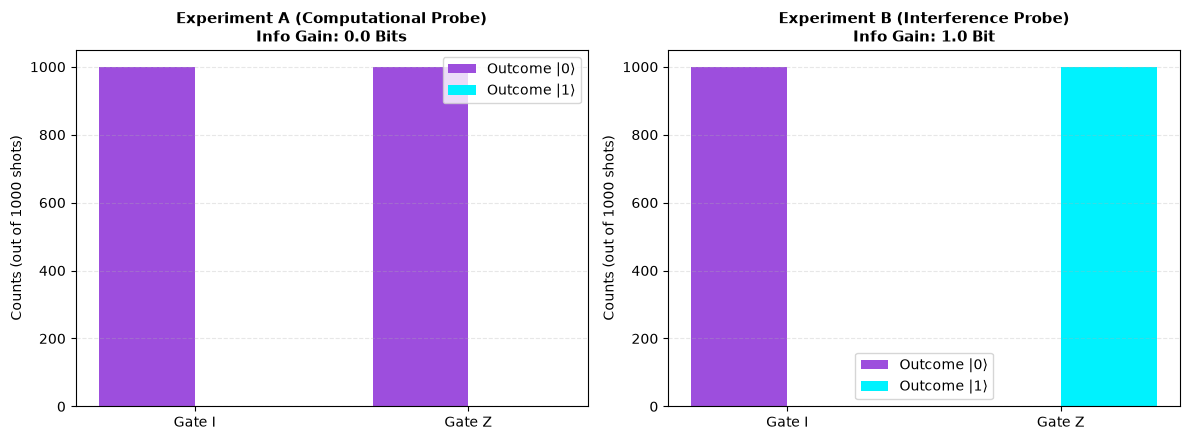

In [4]:
benchmark = run_classical_baseline_benchmark(shots=1000)

# Plot Comparative Bar Chart
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Exp A Plot
labels = ['Gate I', 'Gate Z']
expA_counts_0 = [res_A_I.counts.get('0', 0), res_A_Z.counts.get('0', 0)]
expA_counts_1 = [res_A_I.counts.get('1', 0), res_A_Z.counts.get('1', 0)]

x = np.arange(len(labels))
width = 0.35

ax1.bar(x - width/2, expA_counts_0, width, label='Outcome |0⟩', color='#9D4EDD')
ax1.bar(x + width/2, expA_counts_1, width, label='Outcome |1⟩', color='#00F2FE')
ax1.set_title('Experiment A (Computational Probe)\nInfo Gain: 0.0 Bits', fontsize=11, fontweight='bold')
ax1.set_ylabel('Counts (out of 1000 shots)')
ax1.set_xticks(x)
ax1.set_xticklabels(labels)
ax1.legend()
ax1.grid(axis='y', linestyle='--', alpha=0.3)

# Exp B Plot
expB_counts_0 = [res_B_I.counts.get('0', 0), res_B_Z.counts.get('0', 0)]
expB_counts_1 = [res_B_I.counts.get('1', 0), res_B_Z.counts.get('1', 0)]

ax2.bar(x - width/2, expB_counts_0, width, label='Outcome |0⟩', color='#9D4EDD')
ax2.bar(x + width/2, expB_counts_1, width, label='Outcome |1⟩', color='#00F2FE')
ax2.set_title('Experiment B (Interference Probe)\nInfo Gain: 1.0 Bit', fontsize=11, fontweight='bold')
ax2.set_ylabel('Counts (out of 1000 shots)')
ax2.set_xticks(x)
ax2.set_xticklabels(labels)
ax2.legend()
ax2.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()


## 5. Comparative Results Summary Table

| Probing Protocol | Target Gate | Ideal P(|0⟩) | Ideal P(|1⟩) | Sampled Counts (1000 Shots) | Mutual Information | Distinguishability |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **Experiment A (Computational)** | Identity ($I$) | 1.00 | 0.00 | `|0⟩: 1000, |1⟩: 0` | **0.0 Bits** | ❌ Indistinguishable |
| **Experiment A (Computational)** | Phase-Flip ($Z$) | 1.00 | 0.00 | `|0⟩: 1000, |1⟩: 0` | **0.0 Bits** | ❌ Indistinguishable |
| **Experiment B (Interference)** | Identity ($I$) | 1.00 | 0.00 | `|0⟩: 1000, |1⟩: 0` | **1.0 Bit** | ✅ 100% Distinguishable |
| **Experiment B (Interference)** | Phase-Flip ($Z$) | 0.00 | 1.00 | `|0⟩: 0, |1⟩: 1000` | **1.0 Bit** | ✅ 100% Distinguishable |

---

## 6. Scientific Interpretation & Limitations

### Scientific Insights
1. **Uninformative Measurement Systems:**  
   Experiment A demonstrates that repeatedly measuring a quantum state in an uninformative basis yields zero new diagnostic information. High shot counts increase statistical confidence of the distribution, but cannot alter the underlying zero mutual information.
2. **Phase-to-Population Conversion:**  
   Quantum phase shifts (like $Z|1\rangle = -|1\rangle$) are invisible to computational measurements without basis rotation. Applying Hadamard transformation $H$ interference maps relative phase shift $\Delta \phi = \pi$ into observable orthogonal populations $|0\rangle$ vs $|1\rangle$.

### Critical Limitations & Hardware Scaling
1. **Physical NISQ Noise:**  
   On real quantum hardware, single-qubit gate errors, readout errors, and phase damping ($T_2$ relaxation) degrade the 100% ideal outcome in Experiment B to $\sim 95\% - 99\%$ fidelity.
2. **Classical Simulatability:**  
   1-qubit circuits are trivial to simulate classically. This project is designed as an interactive educational experience rather than a demonstration of quantum computational advantage.
3. **Future Extension:**  
   Extending PHASE//TRACE to 2-qubit entangling gates ($CNOT$, $CZ$, $SWAP$) and full Pauli Quantum Process Tomography (QPT).
